# Curriculum learning for solar-filament instance segmentation (MAGFiLO 2026)
Reproducible walkthrough of the study: data, controlled E1–E5 comparison (YOLO11m-seg, 5 seeds each),
inference tuning, final ensemble and submission validation. Heavy steps (training/inference) are given as
shell commands; this notebook reads their saved outputs so it runs in seconds. Run from the repo root.

In [1]:
import os, json, pandas as pd, numpy as np
from pathlib import Path
from IPython.display import Image, display
from scipy import stats
os.chdir(Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent)
pd.set_option('display.precision', 4)

## 1. Reproduce the pipeline (commands, GPU 1, run inside tmux)
```bash
python -m src.data.prepare                          # EDA, annotation checks, difficulty groups, grouped split, YOLO labels
pytest -q tests/                                    # pipeline tests
CUDA_VISIBLE_DEVICES=1 scripts/run_queue.sh "E1:0 E1:1 ... E5:4"   # 25 controlled runs -> results/<EXP>_s<seed>/
python -m src.evaluation.aggregate                  # experiment_results.csv, reports/summary_*, paired stats, figures
python -m src.evaluation.infer_sweep --weights results/E5_s*/weights/last.pt --imgsz 1024 1280 1536 --conf ...
python -m src.evaluation.ensemble_sweep ...         # mask-voting ensemble sweep -> reports/ensemble_sweep.csv
python -m src.inference.make_ensemble_submission --weights results/E5_s{0..4}/weights/last.pt \
       --imgsz 1536 --vote 0.5 --conf 0.45 --out submissions/E5_ens5_1536.csv
python -m src.evaluation.visualize                  # qualitative figure
```

## 2. Dataset

In [2]:
eda = json.load(open('reports/eda/summary.json'))
print({k: eda[k] for k in ['n_records','n_physical_images','n_test_images','n_annotations','records_per_image']})
print(json.load(open('data/processed/split_meta.json')))
imgs = pd.read_csv('data/processed/images.csv')
display(imgs.groupby(['split','difficulty']).size().unstack())

{'n_records': 1154, 'n_physical_images': 707, 'n_test_images': 180, 'n_annotations': 8199, 'records_per_image': {'1': 411, '2': 145, '3': 151}}
{'seed': 42, 'n_folds': 5, 'holdout_fold': 0, 'group_key': 'month(YYYYMM)', 'threshold_easy_max': 5.0, 'threshold_medium_max': 9.0, 'rule': 'easy: d<=t1, medium: t1<d<=t2, hard: d>t2; d=median per-annotator count; thresholds from holdout-train only', 'split_id': 'month5fold_seed42_f0'}


difficulty,easy,hard,medium
split,,,
train,204,182,180
val,63,30,48


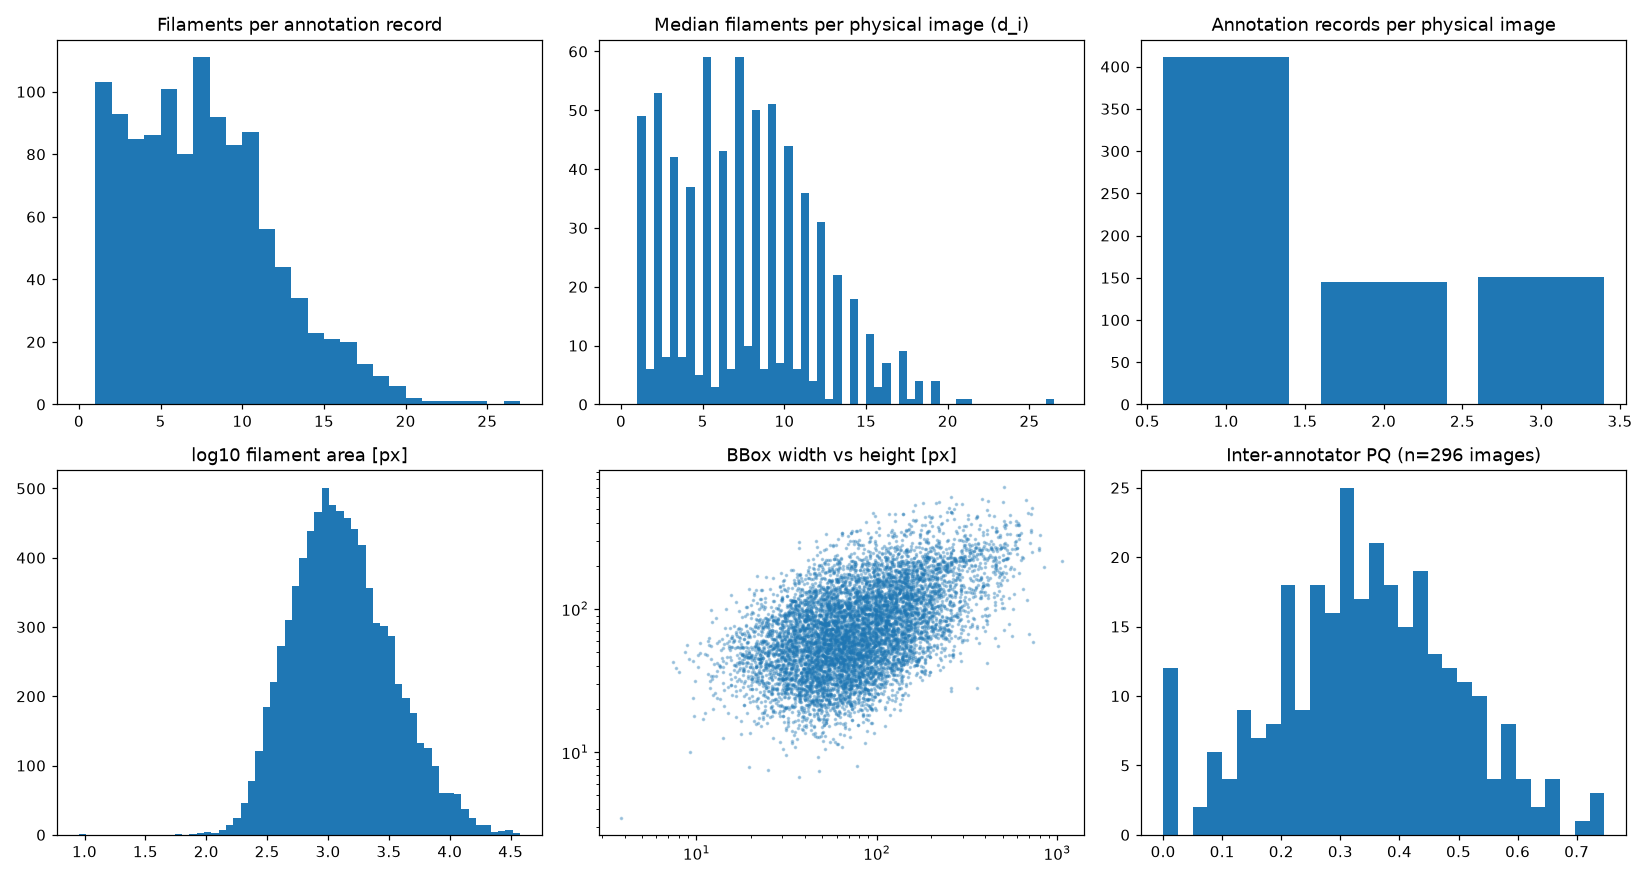

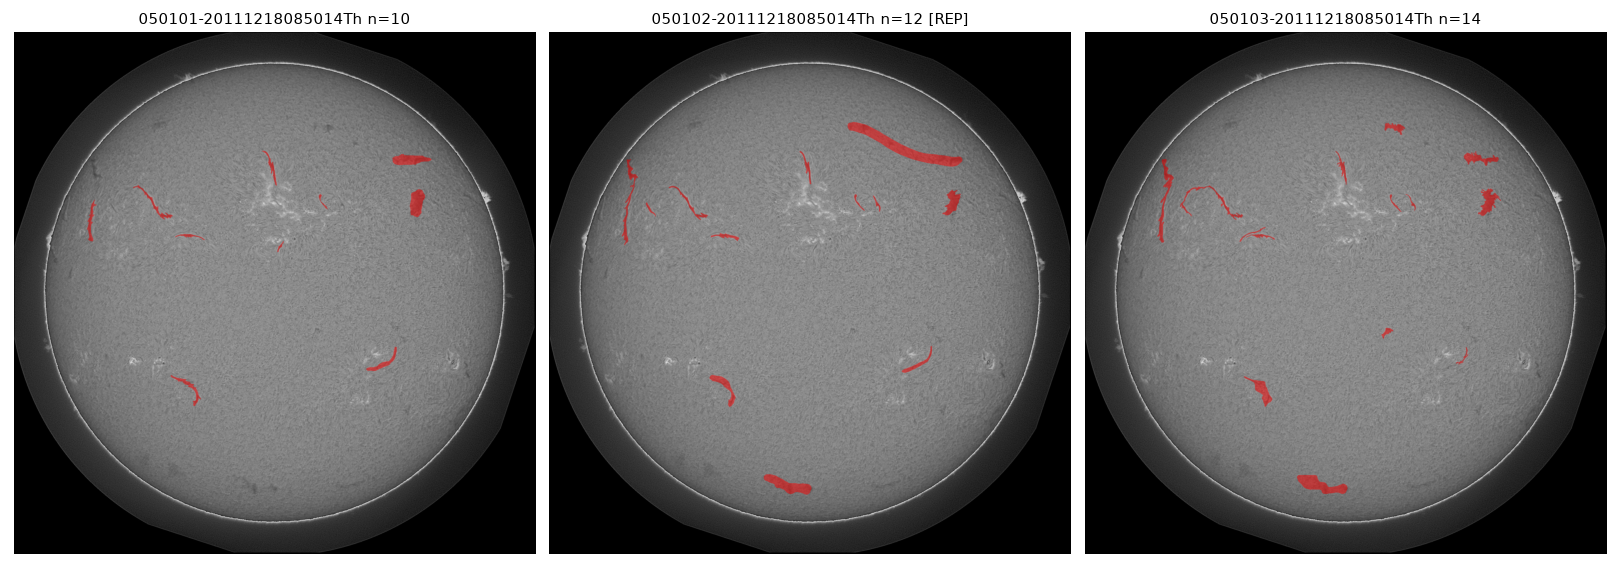

In [3]:
display(Image('reports/eda/dataset_statistics.png')); display(Image('reports/eda/annotator_disagreement_example.png'))

## 3. Controlled comparison E1–E5
All runs share initialisation, update budget (1800 updates, batch 16), augmentation and post-processing; only the
sampling schedule differs. E1 random · E2 30% random subset (size-matched control) · E3 easy+medium→all ·
E4 medium+hard→all (anti-curriculum) · E5 easy→easy+medium→all.

In [4]:
res = pd.read_csv('experiment_results.csv')
summ = res.groupby('experiment')[['PQ','SQ','RQ','FP','FN','PQ_easy','PQ_medium','PQ_hard','PQ_best_ckpt']].agg(['mean','std'])
display(summ)

PQ              SQ              RQ             FP           \
              mean     std    mean     std    mean     std   mean      std   
experiment                                                                   
E1          0.3541  0.0050  0.6337  0.0024  0.5588  0.0066  593.8  33.6110   
E2          0.3514  0.0043  0.6331  0.0019  0.5550  0.0055  631.6  29.9048   
E3          0.3535  0.0053  0.6325  0.0025  0.5590  0.0099  590.4  21.6518   
E4          0.3476  0.0046  0.6330  0.0026  0.5492  0.0075  647.4  27.9159   
E5          0.3578  0.0052  0.6324  0.0012  0.5657  0.0075  567.8  29.4907   

               FN          PQ_easy         PQ_medium         PQ_hard          \
             mean      std    mean     std      mean     std    mean     std   
experiment                                                                     
E1          592.8   5.5408  0.3714  0.0098    0.3404  0.0072  0.3574  0.0071   
E2          585.2  12.3976  0.3714  0.0095    0.3404  0.0065  0.3494  0.0066   
E3          593.6  16.3951  0.3690  0.0126    0.3390  0.0051  0.3595  0.0062   
E4          590.2  10.2567  0.3588  0.0069    0.3341  0.0051  0.3561  0.0100   
E5          590.0   6.2048  0.3726  0.0090    0.3454  0.0037  0.3612  0.0058   

           PQ_best_ckpt          
                   mean     std  
experiment                       
E1               0.3607  0.0063  
E2               0.3648  0.0088  
E3               0.3589  0.0039  
E4               0.3612  0.0083  
E5               0.3598  0.0047

In [5]:
rows = []
piv = res.pivot(index='seed', columns='experiment', values='PQ')
for a, b in [('E2','E1'),('E3','E1'),('E4','E1'),('E5','E1'),('E3','E2'),('E3','E4'),('E5','E3')]:
    d = piv[a] - piv[b]
    rows.append(dict(cmp=f'{a}-{b}', mean_diff=d.mean(), wins=int((d>0).sum()), t_p=stats.ttest_rel(piv[a], piv[b]).pvalue))
display(pd.DataFrame(rows))
display(pd.read_csv('reports/paired_comparisons.csv'))

,cmp,mean_diff,wins,t_p
0,E2-E1,-0.0027,2,0.4882
1,E3-E1,-0.0006,2,0.8896
2,E4-E1,-0.0064,0,0.0096
3,E5-E1,0.0037,5,0.0223
4,E3-E2,0.0021,5,0.0441
5,E3-E4,0.0059,4,0.1628
6,E5-E3,0.0043,4,0.3377


,comparison,n_seeds,mean_diff,std_diff,wins,paired_t_p,wilcoxon_p,pooled_PQ_diff,boot_ci_low,boot_ci_high
0,E3-E1,5,-0.0006,0.0085,2,0.8896,1.0000,-0.0005,-0.0060,0.0051
1,E3-E2,5,0.0021,0.0016,5,0.0441,0.0625,0.0021,-0.0035,0.0078
2,E2-E1,5,-0.0027,0.0079,2,0.4882,0.6250,-0.0027,-0.0081,0.0031
3,E4-E1,5,-0.0064,0.0031,0,0.0096,0.0625,-0.0064,-0.0119,-0.0007
4,E5-E1,5,0.0037,0.0023,5,0.0223,0.0625,0.0037,-0.0022,0.0096
5,E3-E4,5,0.0059,0.0077,4,0.1628,0.1875,0.0059,-0.0011,0.0132
6,E5-E3,5,0.0043,0.0087,4,0.3377,0.4375,0.0042,-0.0019,0.0097


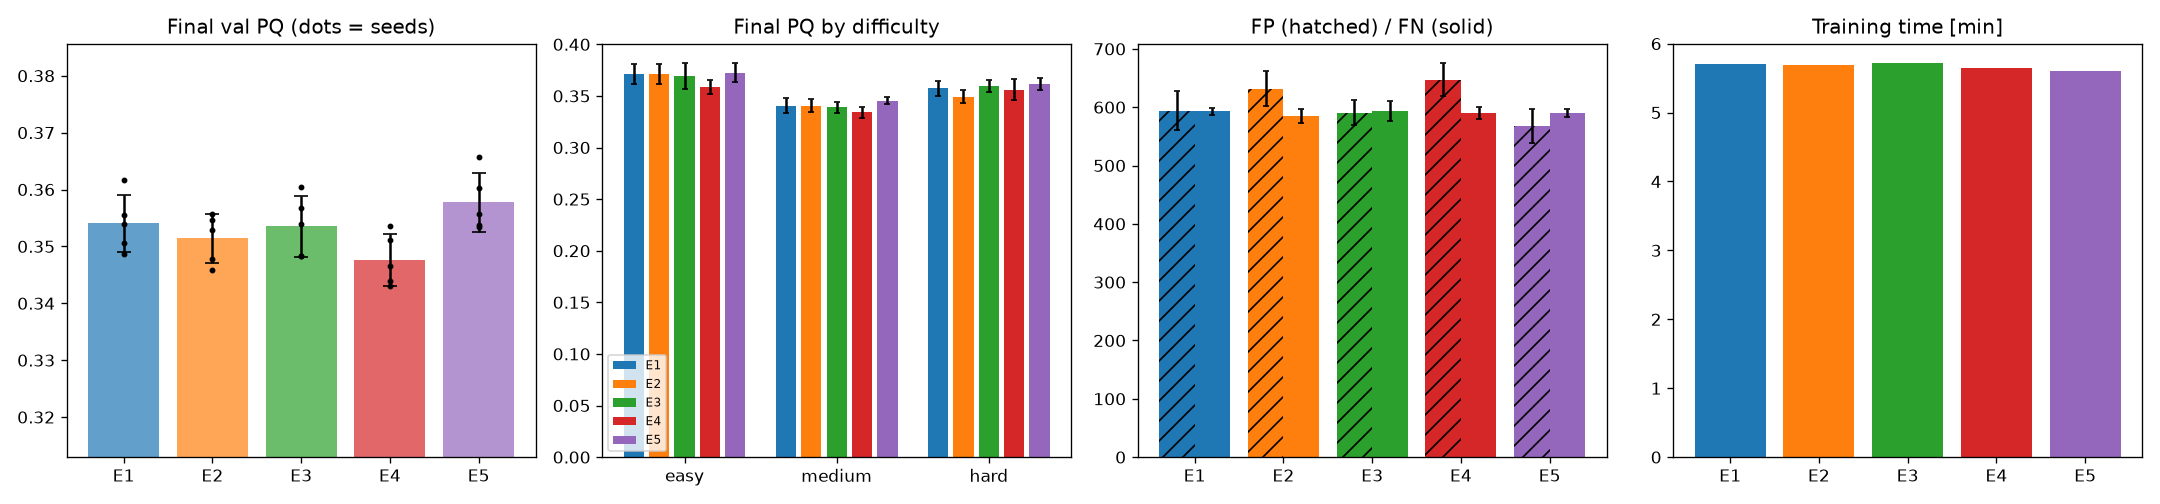

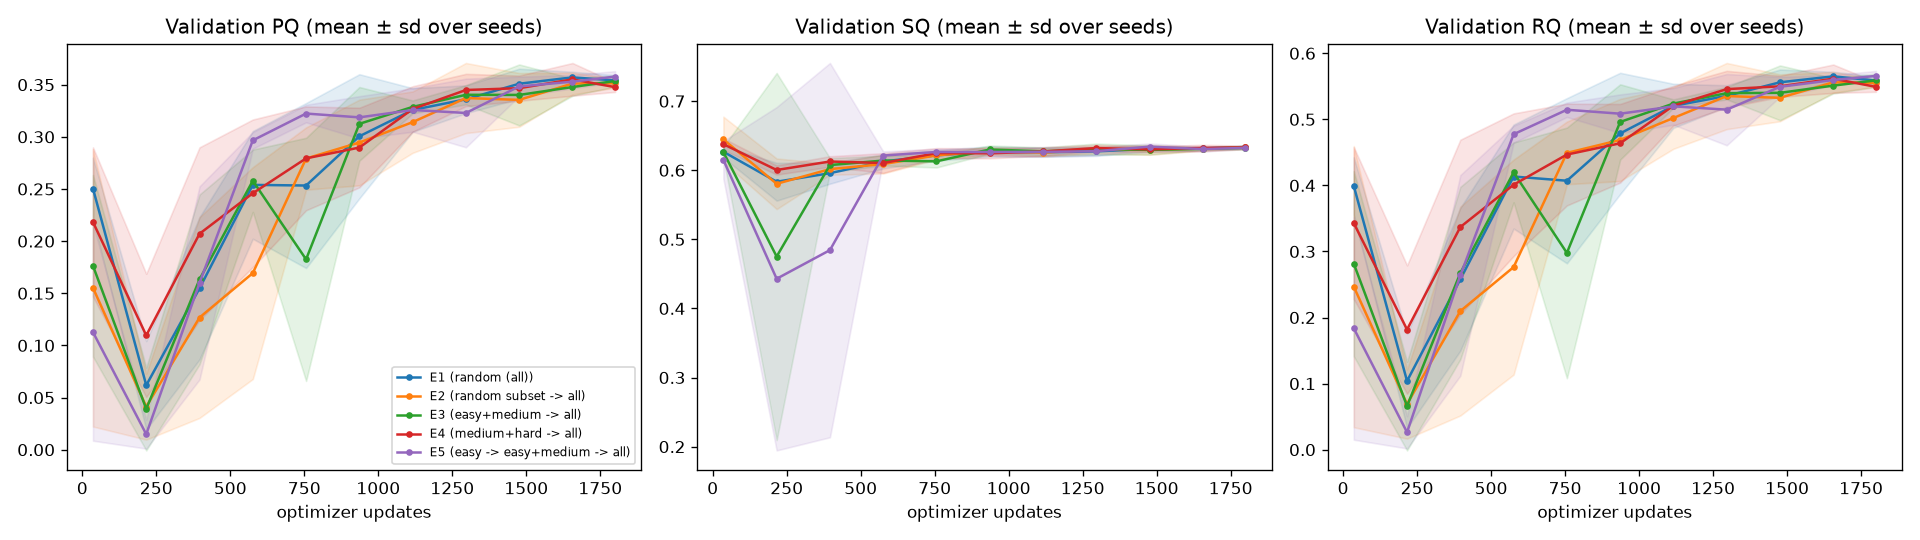

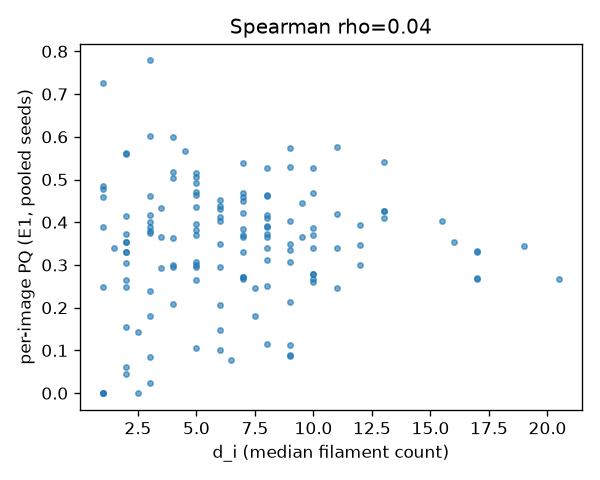

In [6]:
for f in ['experiment_comparison','val_curves_vs_updates','difficulty_proxy']: display(Image(f'reports/figures/{f}.png'))

## 4. Inference tuning (no retraining) and ensemble

In [7]:
display(pd.read_csv('reports/infer_sweep/summary.csv').head(8))
display(pd.read_csv('reports/infer_sweep_long/summary.csv').head(3))
ens = pd.read_csv('reports/ensemble_sweep.csv').sort_values('PQ', ascending=False)
display(ens.head(8))

,imgsz,conf,mean,std,count
0,1536,0.45,0.3992,0.0032,5
1,1536,0.40,0.3984,0.0043,5
2,1536,0.50,0.3943,0.0062,5
3,1280,0.40,0.3939,0.0029,5
4,1280,0.35,0.3926,0.0029,5
5,1536,0.35,0.3917,0.0068,5
6,1280,0.45,0.3882,0.0021,5
7,1280,0.30,0.3880,0.0053,5


,imgsz,conf,mean,std,count
0,1536,0.55,0.3769,0.0137,2
1,1536,0.60,0.3756,0.0108,2
2,1536,0.50,0.3746,0.0122,2


,n_models,pre,vote,conf,PQ,SQ,RQ,TP,FP,FN
19,5,0.2,0.6,0.45,0.4175,0.6639,0.6288,787,372,557
12,5,0.2,0.5,0.45,0.4173,0.6638,0.6286,787,373,557
18,5,0.2,0.6,0.40,0.4161,0.6629,0.6278,829,468,515
11,5,0.2,0.5,0.40,0.4159,0.6628,0.6276,829,469,515
5,5,0.2,0.4,0.45,0.4091,0.6593,0.6206,777,383,567
17,5,0.2,0.6,0.35,0.4090,0.6611,0.6187,865,587,479
10,5,0.2,0.5,0.35,0.4090,0.6607,0.6190,866,588,478
4,5,0.2,0.4,0.40,0.4080,0.6581,0.6200,819,479,525


## 5. Qualitative comparison (validation)

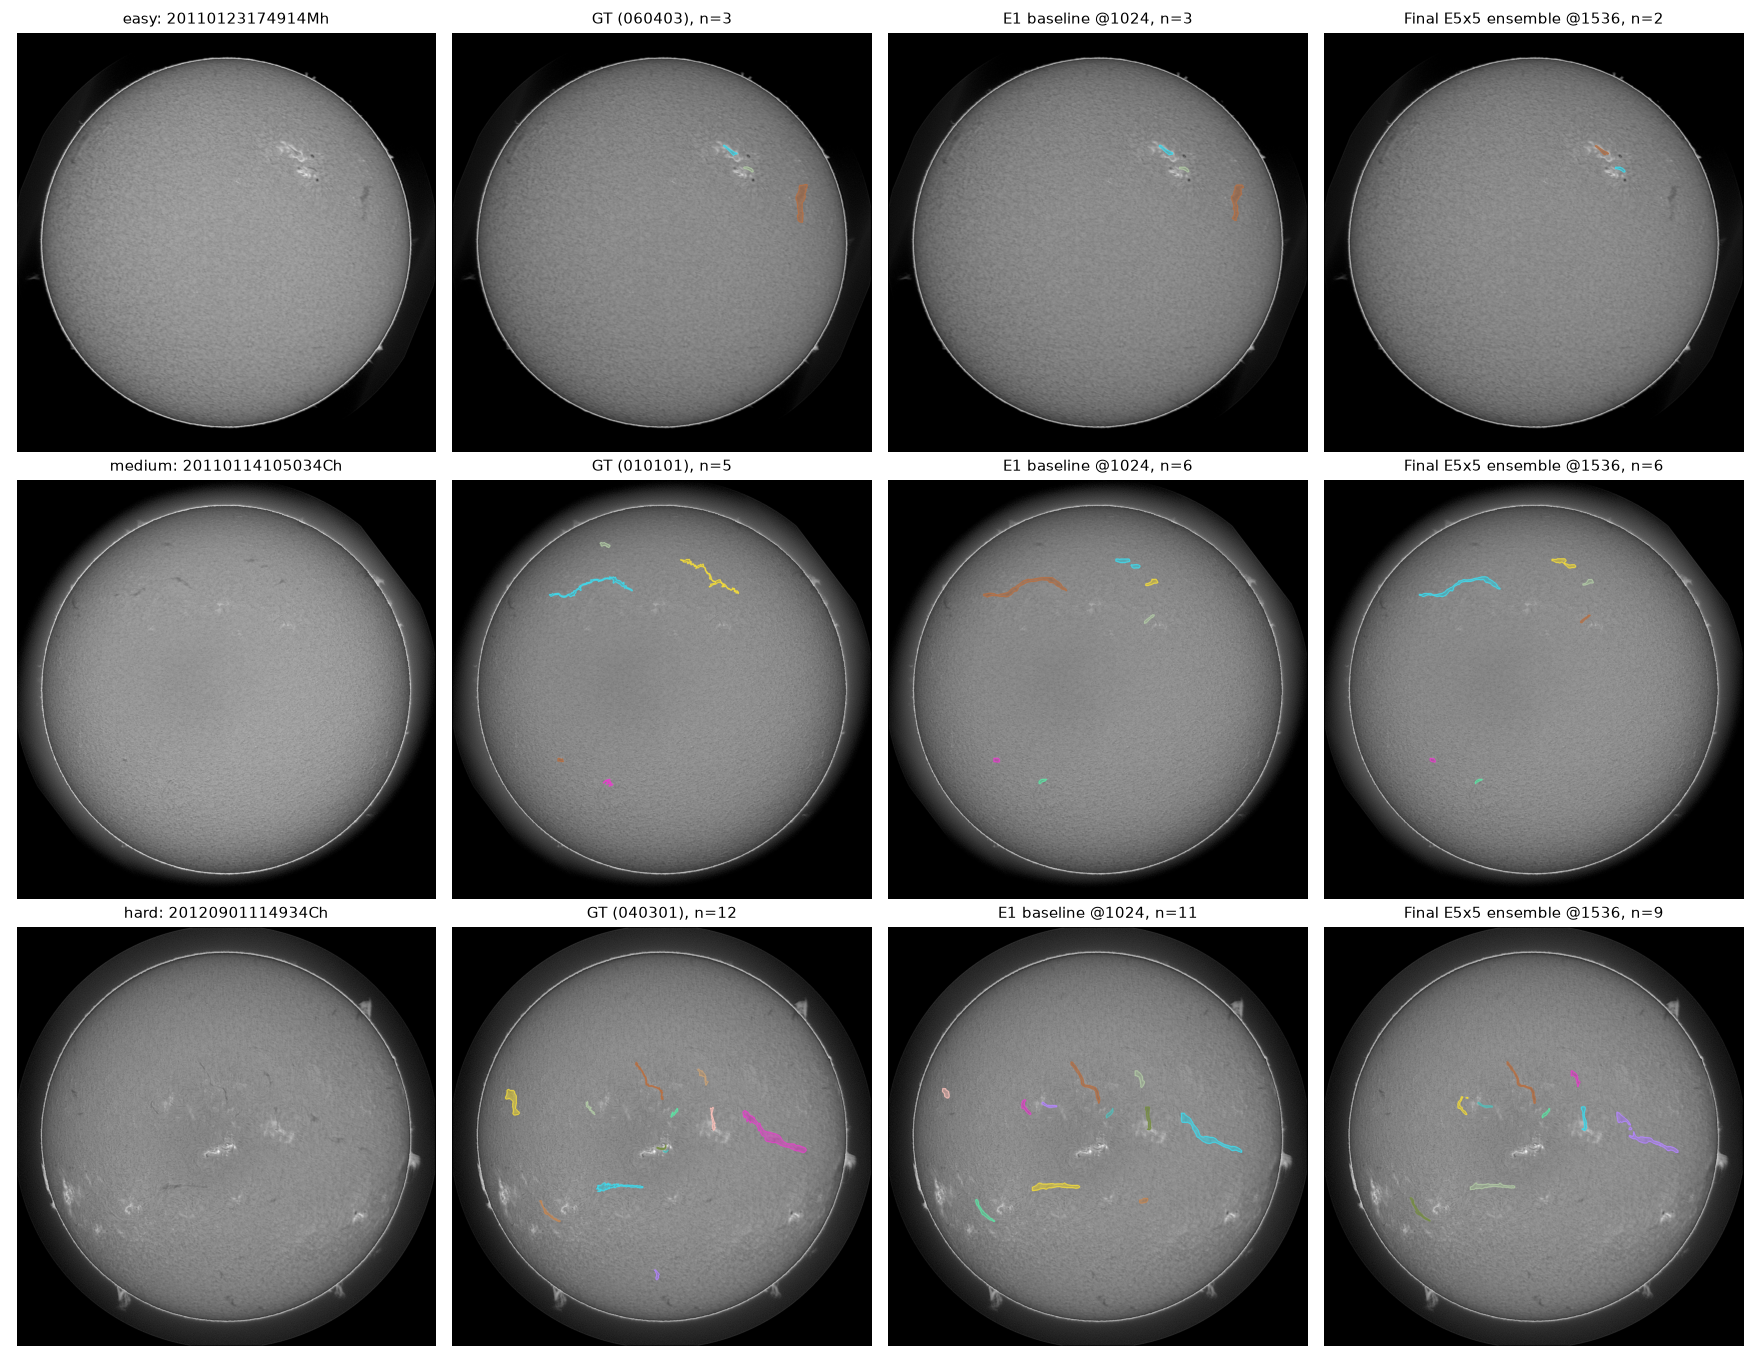

In [8]:
display(Image('reports/figures/qualitative_val.png'))

## 6. Final submission validation

In [9]:
from src.inference.make_submission import TEST, validate_submission
sub = pd.read_csv('submissions/E5_ens5_1536.csv')
stems = [p.stem for p in sorted(TEST.glob('*.jp*g'))]
print('rows', len(sub), '| test images', len(stems), '| errors', validate_submission(sub, stems))
print(json.load(open('submissions/E5_ens5_1536.json')))
display(sub.head())

rows 1099 | test images 180 | errors []
{'weights': ['results/E5_s0/weights/last.pt', 'results/E5_s1/weights/last.pt', 'results/E5_s2/weights/last.pt', 'results/E5_s3/weights/last.pt', 'results/E5_s4/weights/last.pt'], 'imgsz': 1536, 'pre': 0.2, 'vote': 0.5, 'conf': 0.45, 'infer': {'imgsz': 1024, 'conf': 0.25, 'iou': 0.5, 'max_det': 100, 'min_area': 30, 'min_keep_frac': 0.5}, 'n_rows': 1099, 'n_test_images': 180, 'images_with_predictions': 176, 'mean_filaments_per_image': 6.105555555555555, 'validation_errors': []}


,filament_id,segmentation_rle
0,20110120105534Ch_1,RjVQ27ho11O1O1O001N1N1100O10O2M2O01000N2K5N2O0...
1,20110120105534Ch_2,T`fi27io11O1O2N2O2O2N0N2O1N1O10O10000O100O1O1O...
2,20110130110334Ch_1,l_Xe2;eo12N3`PNEUo1d0O1O001O01000O3M2O1N2O1O2O...
3,20110214175414Mh_1,T]f[2>_o14M2M4M201N1O2O0oNYOgRNj0Wm1YOfRNh0Ym1...
4,20110214175414Mh_2,`]^b29go11O001O001O010O01O01O00000O100000001O0...
